# 5. A new setup with a few labeled surfaces

With no label a new setup does not work (`4_new_setup.ipynb`). Here we allow ourselves a short calibration:
somebody labels **k surfaces per family** on the new setup.

We use the vibration only. Each recording becomes one vector from BEATs, a pretrained audio model that we do
not train. On top we fit a small classifier.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FAMILIES = ["wood", "metal", "textile", "polymer"]

## The data

One BEATs vector per recording, made in `1_data.ipynb`. Cluster, LMT108 and SENS3 are our three development
setups. HaTT is the test we kept locked.

In [2]:
saved = np.load("cache/vibration_vectors.npz", allow_pickle=True)
vectors = saved["vectors"]
info = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family"]})

info.groupby("dataset").agg(recordings=("family", "size"), surfaces=("surface", "nunique"))

,recordings,surfaces
dataset,,
cluster,2880,72
hatt,172,43
lmt108,720,36
sens3,2400,30


## The classifier

Standardize, keep at most 256 principal components, logistic regression.
Every (dataset, family) group gets the same total weight.

In [3]:
def train_and_test(train, test):
    part = info[train]
    weight = 1 / part.groupby(["dataset", "family"]).family.transform("size").to_numpy()
    model = make_pipeline(
        StandardScaler(), PCA(min(256, train.sum() - 1), random_state=0), LogisticRegression(max_iter=3000)
    )
    model.fit(vectors[train], part.family, logisticregression__sample_weight=weight / weight.mean())
    return model.predict(vectors[test])


def pick_surfaces(setup, k, rng):
    # k surfaces per family of this setup, at random
    surfaces = info[info.dataset == setup][["surface", "family"]].drop_duplicates()
    picked = [rng.choice(surfaces.surface[surfaces.family == f], k, replace=False) for f in FAMILIES]
    return info.surface.isin(np.concatenate(picked)).to_numpy()

## First on the development setups: alone, or with the other setups?

Each of the three setups plays the new one in turn. We compare two ways of training:

- only the k labeled surfaces of the new setup;
- the two other setups + the k labeled surfaces.

In [4]:
development = ["cluster", "lmt108", "sens3"]
rows = []
for number, setup in enumerate(development):
    new = (info.dataset == setup).to_numpy()
    others = info.dataset.isin(development).to_numpy() & ~new
    for k in [1, 2]:
        for draw in range(10):
            labeled = pick_surfaces(setup, k, np.random.default_rng([number, k, draw]))
            test = new & ~labeled
            for name, train in [("labels only", labeled), ("other setups + labels", others | labeled)]:
                score = balanced_accuracy_score(info.family[test], train_and_test(train, test))
                rows.append({"new setup": setup, "k": k, "training": name, "score": score})

development_scores = pd.DataFrame(rows).groupby(["training", "new setup", "k"]).score.mean().unstack("k")
development_scores.to_csv("results/few_labels_development.csv")
development_scores.round(2)

k                                   1     2
training              new setup            
labels only           cluster    0.48  0.52
                      lmt108     0.61  0.67
                      sens3      0.38  0.48
other setups + labels cluster    0.41  0.46
                      lmt108     0.38  0.54
                      sens3      0.36  0.44

The labels of the new setup alone do better than with the other setups added, on the three setups.
So we froze this choice (BEATs, labels of the new setup only) **before** looking at HaTT, and wrote the pass mark:
at least 0.45 with 2 surfaces per family.

## The locked test on HaTT

HaTT is a steel tip held by hand, from another lab. 43 surfaces, and only 3 of them are wood.

- k = 0: a classifier trained on the three development setups, no HaTT label.
- k = 1 and k = 2: only the labeled HaTT surfaces, 20 random draws.

The interval comes from drawing the test surfaces again, with replacement, 500 times.

In [5]:
def score_with_interval(test, predicted):
    right = (predicted == info.family[test]).groupby([info.family[test], info.surface[test]]).agg(["sum", "count"])
    recall = [right.loc[f, "sum"].sum() / right.loc[f, "count"].sum() for f in FAMILIES]
    rng = np.random.default_rng(42)
    draws = []
    for _ in range(500):
        again = []
        for f in FAMILIES:
            pick = rng.choice(len(right.loc[f]), len(right.loc[f]))
            again.append(right.loc[f, "sum"].to_numpy()[pick].sum() / right.loc[f, "count"].to_numpy()[pick].sum())
        draws.append(np.mean(again))
    return [np.mean(recall), np.percentile(draws, 2.5), np.percentile(draws, 97.5), *recall]


hatt = (info.dataset == "hatt").to_numpy()
rows = [[0, *score_with_interval(hatt, train_and_test(~hatt, hatt))]]
for k in [1, 2]:
    for draw in range(20):
        labeled = pick_surfaces("hatt", k, np.random.default_rng([99, k, draw]))
        test = hatt & ~labeled
        rows.append([k, *score_with_interval(test, train_and_test(labeled, test))])

locked = pd.DataFrame(rows, columns=["k", "score", "low", "high", *FAMILIES]).groupby("k").mean()
locked.to_csv("results/few_labels_locked_test.csv")
locked.round(2)

,score,low,high,wood,metal,textile,polymer
k,,,,,,,
0,0.42,0.32,0.52,0.83,0.40,0.34,0.10
1,0.53,0.44,0.63,0.99,0.44,0.51,0.19
2,0.64,0.54,0.76,1.00,0.63,0.61,0.33


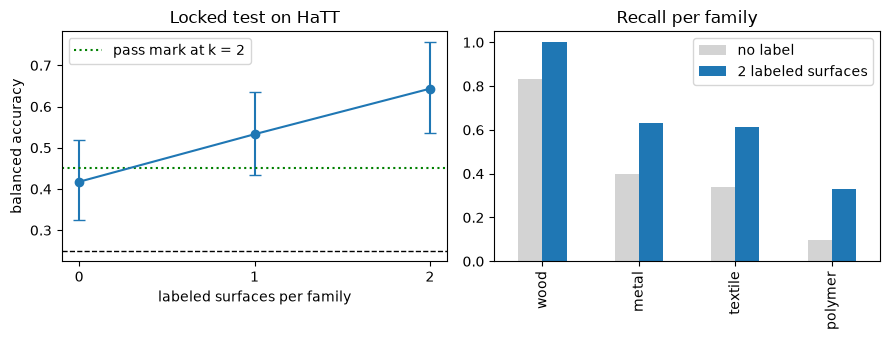

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].errorbar(locked.index, locked.score, [locked.score - locked.low, locked.high - locked.score], marker="o", capsize=4)
axes[0].axhline(0.25, color="black", linestyle="--", linewidth=1)
axes[0].axhline(0.45, color="green", linestyle=":", label="pass mark at k = 2")
axes[0].set_xticks([0, 1, 2])
axes[0].set_xlabel("labeled surfaces per family")
axes[0].set_ylabel("balanced accuracy")
axes[0].set_title("Locked test on HaTT")
axes[0].legend()
locked.loc[[0, 2], FAMILIES].T.plot.bar(ax=axes[1], color=["lightgrey", "tab:blue"])
axes[1].set_title("Recall per family")
axes[1].legend(["no label", "2 labeled surfaces"])
plt.tight_layout()
plt.savefig("results/few_labels_locked_test.png", dpi=120)

## What we see

- With 2 labeled surfaces per family: **0.64**, above the 0.45 we had set. With no label: 0.42.
- This is the only locked test of the project that passed.
- Polymer stays the weak family (0.33).
- Be careful with wood: there is only one wood surface left to test at k = 2.
- Adding the other setups does not help. We find the same thing with CLAP in `6_fine_tuning.ipynb`.